In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
train = pd.read_csv("train_preprocessed.csv", low_memory=False)
print("Shape:", train.shape)
train.head()

Shape: (1017209, 32)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,Month,Day,WeekOfYear,IsWeekend,MonthPeriod,MonthSin,MonthCos,DayOfWeekSin,DayOfWeekCos,Open_was_missing
0,1,5,2015-07-31,5263,555,1,1,0,1,c,...,7,31,31,0,End,-0.5,-0.866025,-0.433884,-0.900969,0
1,2,5,2015-07-31,6064,625,1,1,0,1,a,...,7,31,31,0,End,-0.5,-0.866025,-0.433884,-0.900969,0
2,3,5,2015-07-31,8314,821,1,1,0,1,a,...,7,31,31,0,End,-0.5,-0.866025,-0.433884,-0.900969,0
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,...,7,31,31,0,End,-0.5,-0.866025,-0.433884,-0.900969,0
4,5,5,2015-07-31,4822,559,1,1,0,1,a,...,7,31,31,0,End,-0.5,-0.866025,-0.433884,-0.900969,0


In [ ]:
print("Dataset information:")
train.info()

print("\nMissing values:")
print(train.isnull().sum().sum())

print("\nDate range:")
print(train["Date"].min(), "to", train["Date"].max())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 32 columns):
 #   Column                                 Non-Null Count    Dtype  
---  ------                                 --------------    -----  
 0   Store                                  1017209 non-null  int64  
 1   DayOfWeek                              1017209 non-null  int64  
 2   Date                                   1017209 non-null  object 
 3   Sales                                  1017209 non-null  int64  
 4   Customers                              1017209 non-null  int64  
 5   Open                                   1017209 non-null  int64  
 6   Promo                                  1017209 non-null  int64  
 7   StateHoliday                           1017209 non-null  object 
 8   SchoolHoliday                          1017209 non-null  int64  
 9   StoreType                              1017209 non-null  object 
 10  Assortment           

In [ ]:
train["Date"] = pd.to_datetime(train["Date"])
print("Date datatype:", train["Date"].dtype)
print("Earliest date:", train["Date"].min())
print("Latest date:", train["Date"].max())

Date datatype: datetime64[ns]
Earliest date: 2013-01-01 00:00:00
Latest date: 2015-07-31 00:00:00


In [ ]:
# Select Store 1
store_data = train[train["Store"] == 1].copy()

# Sort by date
store_data = store_data.sort_values("Date")

print("Store 1 data shape:", store_data.shape)
print("Date range:", store_data["Date"].min(), "to", store_data["Date"].max())

print("\nFirst 5 records:")
print(store_data[["Date", "Sales", "Customers", "Open"]].head())

Store 1 data shape: (942, 32)
Date range: 2013-01-01 00:00:00 to 2015-07-31 00:00:00

First 5 records:
              Date  Sales  Customers  Open
1016095 2013-01-01      0          0     0
1014980 2013-01-02   5530        668     1
1013865 2013-01-03   4327        578     1
1012750 2013-01-04   4486        619     1
1011635 2013-01-05   4997        635     1


In [ ]:
# Check duplicate dates
print("Duplicate dates:", store_data["Date"].duplicated().sum())

# Check expected number of calendar days
expected_days = pd.date_range(
    start=store_data["Date"].min(),
    end=store_data["Date"].max(),
    freq="D"
)

print("Expected calendar days:", len(expected_days))
print("Actual records:", len(store_data))

# Check missing dates
missing_dates = expected_days.difference(store_data["Date"])

print("Missing dates:", len(missing_dates))

Duplicate dates: 0
Expected calendar days: 942
Actual records: 942
Missing dates: 0


In [ ]:
# Extract Date and Sales
sales_series = store_data[["Date", "Sales"]].copy()

# Set Date as index
sales_series = sales_series.set_index("Date")

# Ensure daily frequency
sales_series = sales_series.asfreq("D")

print("Time series created successfully!")
print("Shape:", sales_series.shape)

sales_series.head()

Time series created successfully!
Shape: (942, 1)


,Sales
Date,
2013-01-01,0
2013-01-02,5530
2013-01-03,4327
2013-01-04,4486
2013-01-05,4997


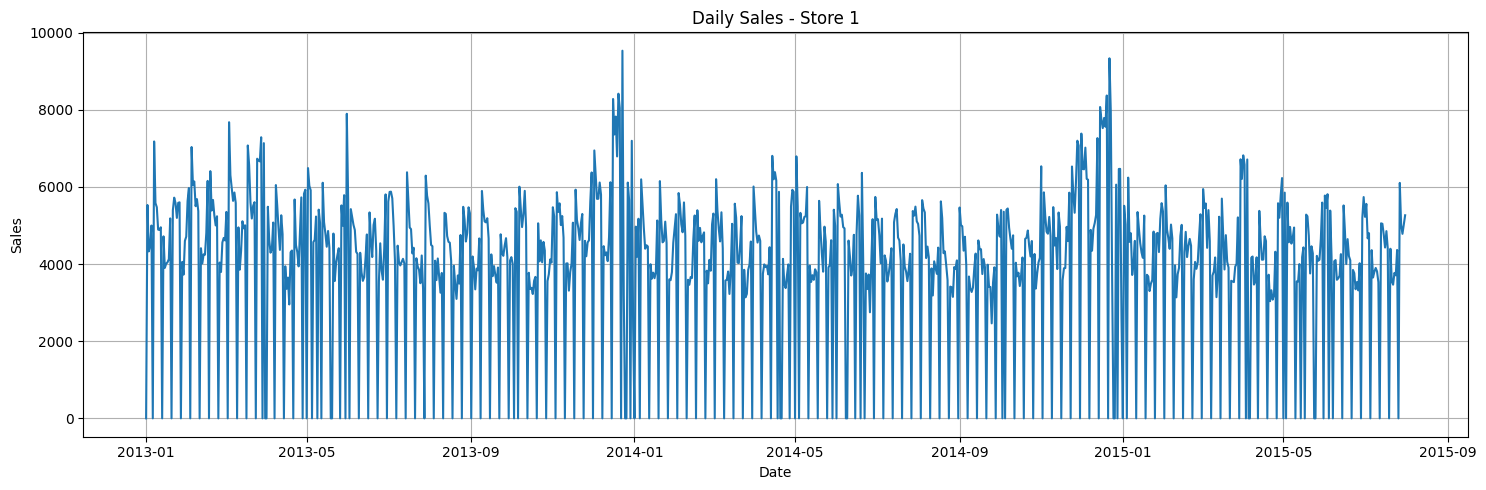

In [ ]:
plt.figure(figsize=(15, 5))

plt.plot(sales_series.index, sales_series["Sales"])

plt.title("Daily Sales - Store 1")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid(True)
plt.tight_layout()
plt.show()

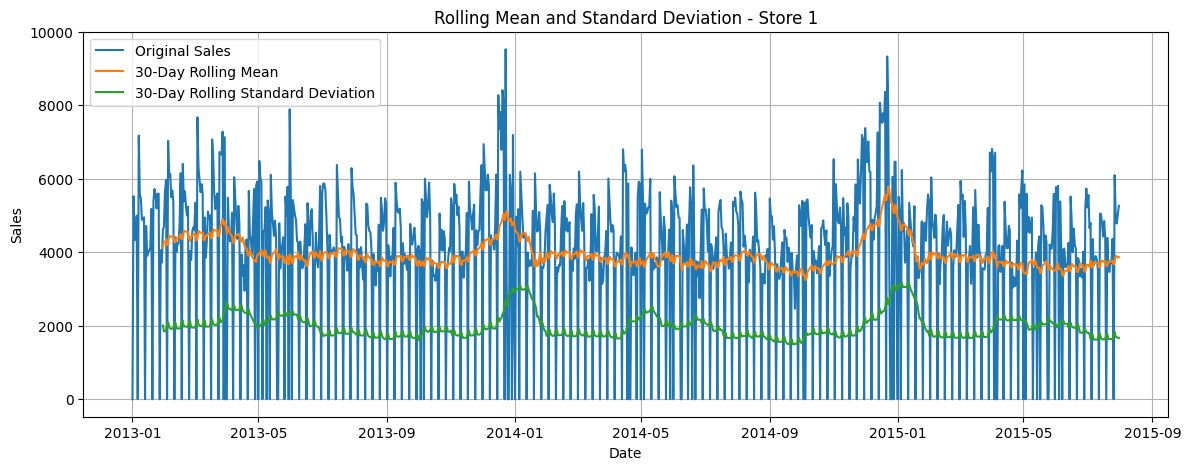

ADF Statistic: -4.368104368168491
p-value: 0.00033788346141425444
Critical Values: {'1%': np.float64(-3.4374778690219956), '5%': np.float64(-2.864686684217556), '10%': np.float64(-2.5684454926748583)}


/tmp/ipykernel_632/3596487414.py:22: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(sales_series["Sales"])


In [ ]:
from statsmodels.tsa.stattools import adfuller

# Calculate rolling statistics
rolling_mean = sales_series["Sales"].rolling(window=30).mean()
rolling_std = sales_series["Sales"].rolling(window=30).std()

# Plot rolling statistics
plt.figure(figsize=(14, 5))

plt.plot(sales_series["Sales"], label="Original Sales")
plt.plot(rolling_mean, label="30-Day Rolling Mean")
plt.plot(rolling_std, label="30-Day Rolling Standard Deviation")

plt.title("Rolling Mean and Standard Deviation - Store 1")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.show()

# Perform ADF test
adf_result = adfuller(sales_series["Sales"])

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Critical Values:", adf_result[4])

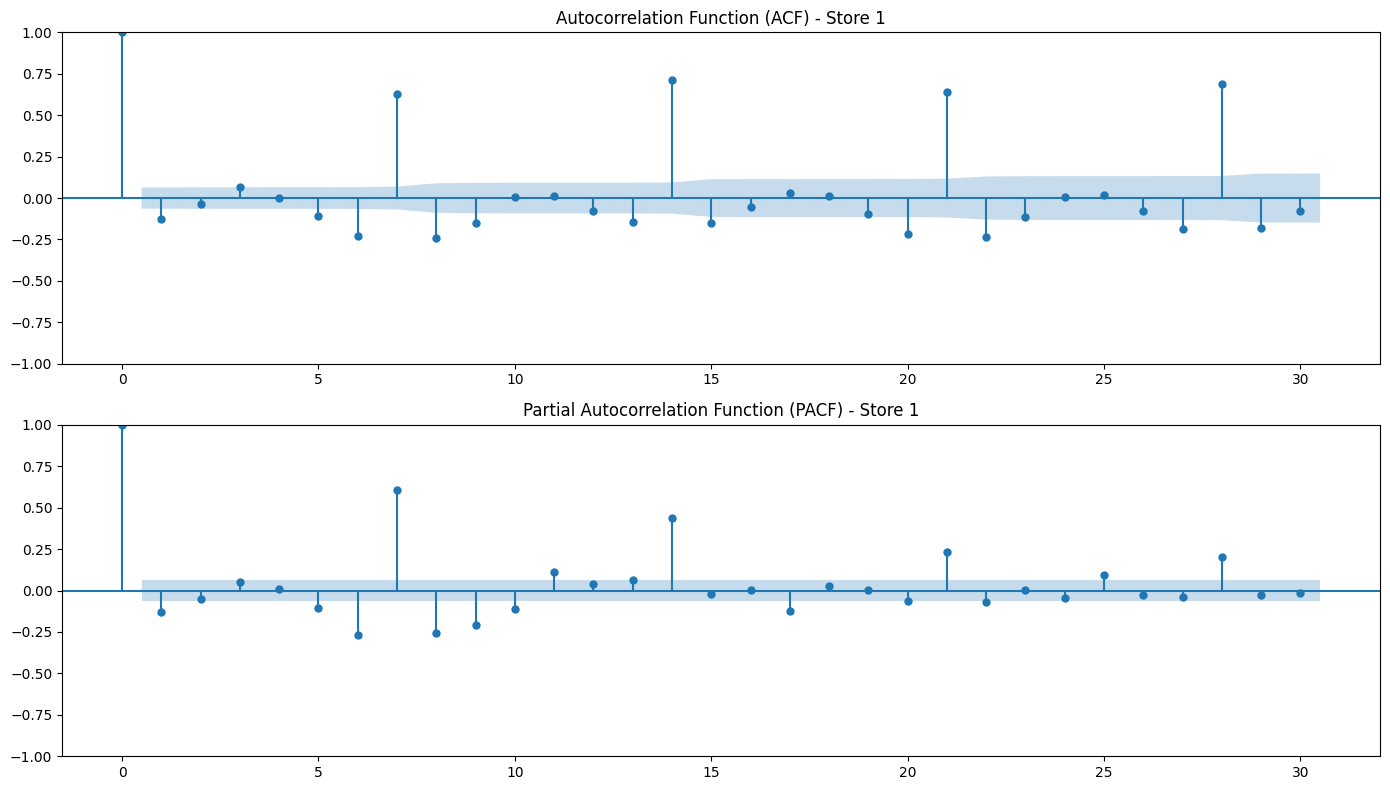

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# ACF plot
plot_acf(sales_series["Sales"], lags=30, ax=axes[0])
axes[0].set_title("Autocorrelation Function (ACF) - Store 1")

# PACF plot
plot_pacf(sales_series["Sales"], lags=30, ax=axes[1])
axes[1].set_title("Partial Autocorrelation Function (PACF) - Store 1")

plt.tight_layout()
plt.show()